In [3]:
import pandas as pd
import numpy as np

In [4]:
#import the xlxs file
raw = pd.read_excel("Excel_Pay_Equity_Analysis.xlsx", sheet_name="RAW_DATA")
print(raw.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18000 entries, 0 to 17999
Data columns (total 20 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   employee_id               18000 non-null  object 
 1   full_name                 18000 non-null  object 
 2   source_dataset            18000 non-null  object 
 3   age                       17447 non-null  float64
 4   gender                    17461 non-null  object 
 5   ethnicity                 13476 non-null  object 
 6   education_level           17134 non-null  object 
 7   years_experience          17800 non-null  float64
 8   tenure_years              17818 non-null  float64
 9   department                18000 non-null  object 
 10  job_title                 18000 non-null  object 
 11  country                   18000 non-null  object 
 12  remote_status             15929 non-null  object 
 13  performance_rating        17154 non-null  object 
 14  perfor

## Stage 0: Setup and load

In [5]:
# Create a copy of dataset & Cleaning.
dfc=raw.copy()
dfc.drop(columns=["Random_Sort"],inplace=True)
print(dfc.head(2))
print(dfc.shape)
print(dfc.info())
print(dfc.describe())

  employee_id           full_name        source_dataset   age gender  \
0     E182875     Courtney Montes  survey_response_2024  48.0   male   
1     E177382  Jennifer Hendricks  survey_response_2024  45.0   Male   

                   ethnicity education_level  years_experience  tenure_years  \
0  Black or African American            PhD.              27.0           4.0   
1                      Asian             BSc              25.0           1.0   

  department   job_title country remote_status  performance_rating  \
0      Legal   Paralegal      UK       On site  Meets Expectations   
1    Finance  Accountant   India        Hybrid             exceeds   

   performance_review_score            hire_date currency     salary_raw  \
0                       NaN  2021-11-07 00:00:00      GBP       Â£50,117   
1                       NaN  2024-10-19 00:00:00      INR  3,520,010 INR   

  pay_band  
0   Band 2  
1   Band 2  
(18000, 19)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1

## Stage 1: Audit

In [6]:
#counting te null values in each coloumn
print(dfc.isnull().sum())
#find out the unique values in coloumn
print("\n")
print("Unique values in each coloumn")
print(dfc.nunique())
#count LEG,DUP
print(f"LEG stating emp_id count :{dfc["employee_id"].astype(str).str.startswith("LEG-").sum()}")
print(f"DUP contain              :{dfc["employee_id"].astype(str).str.contains("_DUP").sum()}")
#cek data type colomn hire_date
print(dfc['hire_date'].map(type).value_counts())
print(dfc["salary_raw"].map(type).value_counts())

employee_id                    0
full_name                      0
source_dataset                 0
age                          553
gender                       539
ethnicity                   4524
education_level              866
years_experience             200
tenure_years                 182
department                     0
job_title                      0
country                        0
remote_status               2071
performance_rating           846
performance_review_score    2762
hire_date                      0
currency                       0
salary_raw                     0
pay_band                       0
dtype: int64


Unique values in each coloumn
employee_id                 18000
full_name                   16136
source_dataset                  3
age                            49
gender                         15
ethnicity                       8
education_level                10
years_experience               41
tenure_years                   16
department            

After Audit Observing and find Problems
1. null values can mostly contain in performance_review score
2. Total employee id is 18000 but the employee_id is not unique it can be duplicate like (LEG) can unique and
   (DUP) 347 it can some duplicate value.
3. i observe in unique coloumn value can be contain the more unique like gender coloum have 16 may white spaces and inconsitant data .
4. hire_date coloumn can contain the data type of date and string .
5.

## Stage 2: Text cleaning

In [7]:
#using strip to removing backspaces
string=["employee_id","full_name","source_dataset","gender","ethnicity","education_level"
,"department","job_title","country","remote_status","performance_rating","pay_band"]
for coll in  string:
    dfc[coll]=dfc[coll].str.strip()
    dfc.isna().sum()

In [8]:

 dfc["gender"].unique()
 dfc["gender"]=dfc["gender"].str.lower()

In [9]:
#gender_maping
gender_map={
    'male':'Male',
    'm':'Male',
    'man':'Male',
    'f':'Female',
    'female':'Female',
    'woman' :'Female',
    'prefer not to say':'Prefer not to say',
    'other':'Prefer not to say',
    'non-binary':'Non-binary',
    'nb':'Non-binary'
}
dfc["gender"]=dfc["gender"].map(gender_map)

In [10]:
#gender unique values
print(dfc["gender"].unique())

['Male' nan 'Female' 'Non-binary' 'Prefer not to say']


In [11]:
#education level formating
#before unique values
print(dfc["education_level"].unique())
dfc["education_level"]=dfc["education_level"].str.lower()
#after lower case unique value
print(dfc["education_level"].unique())

['PhD.' 'BSc' 'PhD' "Master's" "Bachelor's" 'Associate Degree'
 "bachelor's degree" 'MSc' nan 'High School' 'Bachelors']
['phd.' 'bsc' 'phd' "master's" "bachelor's" 'associate degree'
 "bachelor's degree" 'msc' nan 'high school' 'bachelors']


In [12]:

#map with education_level
level_map={
    'phd.':'PhD',
    'phd':'PhD',
    'bsc':"Bachelor's",
    "bachelor's":"Bachelor's",
    "bachelor's degree":"Bachelor's",
    'bachelors':"Bachelor's",
    'msc' :"Master's" ,
    "master's" :"Master's",
    'associate degree':'Associate degree',
    'high school':'High School'
}
dfc["education_level"]=dfc["education_level"].map(level_map)

In [13]:
#unique values of education level
dfc["education_level"].unique()


array(['PhD', "Bachelor's", "Master's", 'Associate degree', nan,
       'High School'], dtype=object)

In [14]:
#remote status Formating
#before unique values
print(dfc["remote_status"].unique())
dfc["remote_status"]=dfc["remote_status"].str.lower()
#after lower case unique value
print(dfc["remote_status"].unique())

['On site' 'Hybrid' nan 'hybrid' 'REMOTE' 'Remote' 'remote' 'On-site'
 'Onsite']
['on site' 'hybrid' nan 'remote' 'on-site' 'onsite']


In [15]:
#remote_status with map
status_map={
    'on site':'Onsite',
    'on-site':'Onsite',
    'onsite':'Onsite',
    'hybrid':'Hybrid',
    'remote':'Remote'
}
dfc["remote_status"]=dfc["remote_status"].map(status_map)

In [16]:
#unique values of remote status
dfc["remote_status"].unique()

array(['Onsite', 'Hybrid', nan, 'Remote'], dtype=object)

In [17]:
#performance_rating format
#before unique values
print(dfc["performance_rating"].unique())
dfc["performance_rating"]=dfc["performance_rating"].str.lower()
#after lower case unique value
print(dfc["performance_rating"].unique())

['Meets Expectations' 'exceeds' 'Exceeds Expectations' 'meets'
 'Below Expectations' nan]
['meets expectations' 'exceeds' 'exceeds expectations' 'meets'
 'below expectations' nan]


In [18]:
#performance_rating wit map
rating_map={
    'meets expectations':'Meets Expectations',
    'meets':'Meets Expectations',
    'below expectations':'Below Expectations',
    'exceeds expectations':'Exceeds Expectations',
    'exceeds':'Exceeds Expectations'
}
dfc["performance_rating"]=dfc["performance_rating"].map(rating_map)


In [19]:
#unique values in performance_rating
dfc["performance_rating"].unique()

array(['Meets Expectations', 'Exceeds Expectations', 'Below Expectations',
       nan], dtype=object)

In [20]:
#Country Formating
#unique value
print(dfc["country"].unique())

['UK' 'India' 'Australia' 'United States' 'Germany' 'France' 'Nigeria'
 'United Kingdom' 'Netherlands' 'South Africa' 'Kenya' 'USA' 'Brazil'
 'Philippines' 'Canada' 'US' 'Singapore']


In [21]:
#country with map
# 5)Country
country_mapping = {
    "India":"India",
    "Australia":"Australia",
    "Germany":"Germany",
    "France":"France",
    "Nigeria":"Nigeria",
    "Netherlands":"Netherlands",
    "South Africa":"South Africa",
    "Kenya":"Kenya",
    "Brazil":"Brazil",
    "Philippines":"Philippines",
    "Canada":"Canada",
    "Singapore":"Singapore",
    "UK":"United Kingdom",
    "United Kingdom":"United Kingdom",
    "US":"United States",
    "USA":"United States",
    "United States":"United States" }

dfc["country"] = dfc["country"].map(country_mapping)

In [22]:
#unique values in country
dfc["country"].unique()

array(['United Kingdom', 'India', 'Australia', 'United States', 'Germany',
       'France', 'Nigeria', 'Netherlands', 'South Africa', 'Kenya',
       'Brazil', 'Philippines', 'Canada', 'Singapore'], dtype=object)

In [23]:
#Department Formating
#before unique values
print(dfc["department"].unique())
dfc["department"]=dfc["department"].str.lower()
#after lower case unique value
print(dfc["department"].unique())

['Legal' 'Finance' 'Engineering' 'Sales' 'Product' 'Data Science' 'HR'
 'Marketing' 'Operations' 'Customer Support' 'IT' 'Design' 'sales'
 'finance' 'design' 'customer support' 'it' 'product' 'marketing' 'legal'
 'engineering' 'operations' 'hr' 'data science']
['legal' 'finance' 'engineering' 'sales' 'product' 'data science' 'hr'
 'marketing' 'operations' 'customer support' 'it' 'design']


In [24]:
#department_maping
dept_map={
    'legal':'Legal',
    'finance':'Finance',
    'engineering':'Engineering',
    'sales':'Sales',
    'product':'Product',
    'data science':'Data Science',
    'hr':'HR',
    'marketing':'Marketing',
    'operations':'Operations',
    'customer support':'Customer Support',
    'it':'IT',
    'design':'Design'
}
dfc["department"]=dfc["department"].map(dept_map)

In [25]:
#checking unique values in department
dfc["department"].unique()

array(['Legal', 'Finance', 'Engineering', 'Sales', 'Product',
       'Data Science', 'HR', 'Marketing', 'Operations',
       'Customer Support', 'IT', 'Design'], dtype=object)

 ## Stage 3: Dates and salary

In [26]:
#dates
#checking datatype
dfc["hire_date"].map(type).value_counts()
#checking null value
dfc["hire_date"].isna().sum()
#change the data type string to date and time
dfc["hire_date"]=pd.to_datetime(dfc["hire_date"],dayfirst=True,errors="coerce")
#latest date
dfc["hire_date"].max()
#oldest date
dfc["hire_date"].min()

Timestamp('2010-07-15 00:00:00')

In [27]:
#checking null value in hire_date coloumn
dfc["hire_date"].isna().sum()

np.int64(0)

In [28]:
# 2) Salary
#checking null value in salary_raw coloumn
dfc["salary_raw"].isna().sum()
#checking datatype of each value in coloumn and count the value
dfc["salary_raw"].map(type).value_counts()
#create a clean coloumn and store all replace things.
dfc["salary_clean"]=dfc["salary_raw"].astype(str).str.replace(r"[^0-9.]","",regex=True).str.replace(r"[iIlL]","", regex=True)
#change the the data type str and int into float with clean salary.
dfc["salary_raw"]=pd.to_numeric(dfc["salary_clean"],errors="coerce")

In [29]:
#checking datatype
dfc["salary_raw"].map(type).value_counts()
#checking null values in te salary colomn
dfc["salary_raw"].isna().sum()

np.int64(0)

**Converting Salary into based on Currency**

In [30]:
# Step 2: coverting salary to the USD currency
#create a dictionary and assign the each country currency
rates = {
    "USD": 1.0000,
    "EUR": 1.1600,
    "GBP": 1.3527,
    "INR": 0.01046,
    "SGD": 0.7890,
    "NGN": 0.000754,
    "ZAR": 0.06196,
    "AUD": 0.7173,
    "BRL": 0.19521,
    "CAD": 0.7209,
    "KES": 0.00773,
    "PHP": 0.01596 }
#store in the salary_usd new coloumn with multiply by salary_raw and currency of each country.
dfc["salary_usd"] =(dfc["salary_raw"] * dfc["currency"].map(rates)).round(2)

In [31]:
#checking the min_salary in salary_usd coloumn
dfc["salary_usd"].min() #245.32

#checking the max_salary in salary_usd coloumn
dfc["salary_usd"].max() #9909426.69

#checking null values in the salary_usd coloumn
dfc["salary_usd"].isna().sum()

np.int64(0)

## Stage 4: Duplicates and blanks

*4a. The _DUP rows*

In [32]:
# Step 1: Make a True/False variable for IDs containing '_DUP'
has_dup = dfc['employee_id'].str.contains('_DUP', na=False)

# Step 2: Make a base ID variable by removing '_DUP'
base_id = dfc['employee_id'].str.replace('_DUP', '', regex=False)

# Step 3: Check whether that base ID exists in the full ID column
twin_exists = base_id.isin(dfc['employee_id'])


# Step 4: Rows to drop = has _DUP AND the twin exists
rows_to_drop = has_dup & twin_exists



In [33]:
# Print counts to check against your checkpoint
print(f"Total rows with _DUP: {has_dup.sum()}")
print(f"Rows to drop: {rows_to_drop.sum()}")
print(f"Rows kept: {len(dfc) - rows_to_drop.sum()}")

# Drop the rows and update dfc
dfc = dfc[~rows_to_drop]

# Final checkpoint row count check
print(f"Total rows left: {len(dfc)}")

Total rows with _DUP: 341
Rows to drop: 73
Rows kept: 17927
Total rows left: 17927


In [34]:
#checking null value employee_id coloumn
dfc["employee_id"].isna().sum()


np.int64(0)

*4b. Blanks*

In [35]:
#Fill the blank value in Age coloumn
#checking null values in age coloumn
dfc["age"].isna().sum() #null value :548

#check the median value age coloumn
dfc["age"].mean()# average value 35.63

#fill the mean value in age coloumn with rounding value
dfc["age"]=dfc["age"].fillna(round(dfc["age"].mean())).astype(int)

#checking null value
dfc["age"].isna().sum()

np.int64(0)

In [36]:
#tenure_years
#create a varriable cuurent and store the current date
current=pd.to_datetime("today")

#convert the hire_date into datetime datatype
dfc["hire_date"]=pd.to_datetime(dfc["hire_date"])

#create a varriable tenure and to proper date format
tenure=(current-dfc["hire_date"]).dt.days/365.25

#create a coloumn tenure_experiance based on hire_date
dfc["tenure_years"]=np.where(tenure<0,0,tenure).round(1)

#round up the tenure_years value
dfc["tenure_years"]=dfc["tenure_years"].round(1)
dfc["tenure_years"]

,tenure_years
0,4.9
1,2.0
2,8.9
3,0.7
4,3.7
...,...
17995,3.0
17996,3.4
17997,0.4
17998,6.3


In [37]:
#gender null value fill
dfc["gender"]=dfc["gender"].fillna("Prefer not to say")
dfc["gender"].isna().sum()

np.int64(0)

In [38]:
#years_experiance null value fill
#Create a varriable ang groupy the pay band based on year experiance and transformm of each pay band average .
group_payband=dfc.groupby("pay_band")["years_experience"].transform('mean').round()

#fill the year_experiance by group_payband
dfc["years_experience"]=dfc["years_experience"].fillna(group_payband)
dfc["years_experience"].isna().sum()

np.int64(0)

In [39]:

#ethinicity coloumn fill null value
dfc["ethnicity"]=dfc["ethnicity"].fillna("Prefer not to say")
#checking unique values
dfc["ethnicity"].unique()

array(['Black or African American', 'Asian', 'Prefer not to say',
       'Hispanic or Latino', 'White', 'Native American',
       'Two or More Races', 'Pacific Islander'], dtype=object)

In [40]:

#education_level fill null values
dfc["education_level"]=dfc["education_level"].fillna(dfc["education_level"].mode()[0])

#checking most repeared value
dfc["education_level"].mode()

#checking null value
dfc["education_level"].isna().sum()


np.int64(0)

In [41]:

#remote status coloumn fill null value
dfc["remote_status"]=dfc["remote_status"].fillna("Unknown")
#checking unique values
dfc["remote_status"].unique()
#checking the
dfc["remote_status"].isna().sum()

np.int64(0)

In [42]:
#performance rating coloumn fill null value
#create a varrible and store the blank values
null=dfc["performance_rating"].isna()

#create a varriable and store N/A
na=dfc["performance_rating"].isin(["N/A"])
#fill null value with not rated
dfc["performance_rating"]=dfc["performance_rating"].mask(null | na,"Not Rated")
#checking null value
dfc["performance_rating"].isna().sum()

np.int64(0)

In [43]:
def clean_job_title(t):
    fixes = {"Ux": "UX", "Devops": "DevOps", "Of": "of",
             "Vp": "VP", "Cfo": "CFO", "Cmo": "CMO", "Coo": "COO",
             "Hr": "HR", "It": "IT", "Seo": "SEO", "Qa": "QA", "Ml": "ML",
             "Ii": "II", "Iii": "III"}
    return " ".join(fixes.get(w, w) for w in t.strip().title().split())

dfc["job_title"] = dfc["job_title"].apply(clean_job_title)

# Check unique values again
dfc['job_title'].nunique()

53

In [44]:
#performance_review_score coloum fill null value
dfc["performance_review_score"]=dfc["performance_review_score"].fillna(dfc["performance_review_score"].mean().round(2))
dfc["performance_review_score"].isna().sum()

np.int64(0)

In [45]:
# 3) Check again to confirm everything is 0
dfc.isnull().sum()

,0
employee_id,0
full_name,0
source_dataset,0
age,0
gender,0
ethnicity,0
education_level,0
years_experience,0
tenure_years,0
department,0


## Stage 5: Outliers

In [46]:
#qurtiles can be calculated and find IQR
Q1=dfc["salary_usd"].quantile(0.25)
Q3=dfc["salary_usd"].quantile(0.75)
IQR=Q3-Q1
#calculate the upperbond and lower bond
upper_bond=Q3+(1.5*IQR)
lower_bond=Q1-(1.5*IQR)
print(f"Quartile 1:{Q1}")
print(f"Quartile 3:{Q3}")
print(f"IQR:{IQR}")
print(f"upper bond:{upper_bond}")
print(f"lower_bond:{lower_bond}")
print(f"mean value:{dfc["salary_usd"].mean()}")
print(f"median value:{dfc["salary_usd"].median()}")
print(f"minimum value:{dfc["salary_usd"].min()}")
print(f"maximum value:{dfc["salary_usd"].max()}")

Quartile 1:33021.16
Quartile 3:56509.865
IQR:23488.704999999994
upper bond:91742.92249999999
lower_bond:-2211.897499999992
mean value:52259.58902995481
median value:43118.47
minimum value:245.32
maximum value:9909426.69


In [47]:

# Create original lower bound
lower_bond_real = 15000

# Create a salary outlier flag based on upper bound and lower bound
dfc["salary_outliar_flag"] = np.where(
    (dfc["salary_usd"] >= upper_bond) | (dfc["salary_usd"] <= lower_bond_real),
    "Yes",
    "No"
)


In [48]:
#checking the skewness of salary_usd
dfc["salary_usd"].skew()# skewness 39.03

#sum of the salary_outliar_flag yes
count_yes=(dfc["salary_outliar_flag"]=="Yes").sum() #count 463
count_no=(dfc["salary_outliar_flag"]=="No").sum() #count 17464

***Stage 6: Categories***  

create A age group  bucket

In [49]:

#create A age group  bucket
dfc["age_group_bucket"]=pd.cut(
    dfc["age"],
    bins=[18,30,40,50,70],
    labels=["18-30","31-40","41-50","51-70"],
    right=True
)
print(dfc["age_group_bucket"].value_counts())

age_group_bucket
31-40    7863
18-30    5093
41-50    4119
51-70     852
Name: count, dtype: int64


Create Tenure Group Bucket

In [50]:
# Create Tenure Group with matching bins and labels (5 edges, 4 labels)
dfc["tenure_group_bucket"]=pd.cut(
   dfc["tenure_years"],
   bins=[-1,2,5,10,20],
   labels=["0-2","3-5","6-10","10+"],
   right=True
 )
dfc["tenure_group_bucket"].value_counts()

,count
tenure_group_bucket,
3-5,6621
0-2,6445
6-10,4663
10+,198


created experiance group Bucket

In [51]:
#created experiance group
dfc["experience_grouup_bucket"]=pd.cut(
    dfc["years_experience"],
    bins=[-1,5,15,45],
    labels=["Junior","Mid-level","Senior"],
    right=True
)
dfc["experience_grouup_bucket"].value_counts()

,count
experience_grouup_bucket,
Senior,8183
Mid-level,6826
Junior,2918


**Change the datatpe coloumn**

In [52]:
dfc=dfc.astype(
    {
        "employee_id":"string",
        "full_name":"string",
        "source_dataset":"string",
        "gender":"string",
        "ethnicity":"string",
        "education_level":"string",
        "department":"string",
        "job_title":"string",
        "country":"string",
        "remote_status":"string",
        "currency":"string",
        "pay_band":"string"
    }
)
dfc.dtypes

,0
employee_id,string[python]
full_name,string[python]
source_dataset,string[python]
age,int64
gender,string[python]
ethnicity,string[python]
education_level,string[python]
years_experience,float64
tenure_years,float64
department,string[python]


## Stage 7: Analysis

In [53]:
#Create a coloumn and store the salary_outliar_flag only No
ok=dfc[dfc["salary_outliar_flag"]=="No"]


Q1 Workforce overview

In [54]:
#value counts  of each department
dfc["department"].value_counts()

#value counts of each gender
dfc["gender"].value_counts()

#value counts of each pay_band
dfc["pay_band"].value_counts()


,count
pay_band,
Band 2,7160
Band 1,6901
Band 3,3522
Band 4,339
Band 5,5


In [55]:
#Metrices of our dataset
dfc[["age","salary_usd","years_experience","tenure_years"]].agg(['median','mean','std','max','min','count'])

,age,salary_usd,years_experience,tenure_years
median,36.000000,4.311847e+04,14.000000,3.30000
mean,35.645172,5.225959e+04,14.685781,3.54361
std,8.551561,1.695036e+05,8.692097,2.57705
max,68.000000,9.909427e+06,40.000000,16.30000
min,20.000000,2.453200e+02,0.000000,0.00000
count,17927.000000,1.792700e+04,17927.000000,17927.00000


Q2 Salary overview

In [56]:
#salary_usd overveiw with aggregate function
dfc["salary_usd"].agg(['mean','median','std'])

,salary_usd
mean,52259.589030
median,43118.470000
std,169503.622647


Q3 Gender pay gap, overall

In [57]:
#calculate the gender gap  with filter ok withit outliars
gender_group=ok.groupby("gender")["salary_usd"].mean()

#ceate a varriable and store the male group averge salary
male_group=gender_group["Male"]

#create a varriable and store the female group average salary
female_group=gender_group["Female"]

#create a varriable and calculate the gender gap between male and female
gender_gap_values=(male_group-female_group)/female_group

#convert the gender_gap into the percentage
gender_gap=(gender_gap_values*100).round(2)
gender_gap



np.float64(6.18)

Q3 Gender gap by department

In [58]:
#create a pivot table for department by gender average salary
dept_pivot=ok.pivot_table(
    index="department",# in index is rows(department)
    columns="gender",#in coloumns is column(gender)
    values="salary_usd",
    aggfunc="mean"
)
#create a new coloumn in the pivot table calculate the pay gap percentge between female and male in each department
dept_pivot["dept_pay_gap_percentage"]=((
    (dept_pivot["Male"]-dept_pivot["Female"])/dept_pivot["Female"])*100).round(2)

#create a varriable for sorting the pay_gap_department
dept_pivots=dept_pivot.sort_values(by="dept_pay_gap_percentage",ascending=False)
dept_pivots["dept_pay_gap_percentage"]


,dept_pay_gap_percentage
department,
Design,8.70
Data Science,8.69
Legal,7.86
Product,7.68
Marketing,7.17
HR,5.83
IT,5.53
Engineering,5.51
Sales,5.21


Q3 Deeper check

In [59]:
#create a deep pivot table to check deep in the pay gap between male and female
male_female=ok[ok['gender'].isin(['Male','Female'])]
deep_pivot=male_female.groupby(['job_title', 'experience_grouup_bucket', 'gender'],observed=True)['salary_usd'].agg(['mean', 'count'])
deep_pivot
gender_table=deep_pivot.unstack("gender")
gender_table['pay_gap']=(gender_table[('mean','Male')]-gender_table[('mean','Female')])/(gender_table[('mean','Female')])*100
gender_table
gender_table['pay_gap'].mean()

np.float64(7.044252004198005)

Q4 Ethnicity

In [60]:
#create a varrible and store group by ethnicity and mean salary
eth_mean=ok.groupby("ethnicity")["salary_usd"].mean()

#craete varriable and store max salary of each ethinicity group
max_eth=eth_mean.max()

#create avarriable and store min salary of each ethincity group
min_eth=eth_mean.min()

#calculte te percentage of
spread_percentage=round(((max_eth-min_eth)/min_eth)*100,2)
spread_percentage

3.64

Q5 Experience

In [61]:
#finding the corelatin between the salary and years of experiance
correlation=ok["years_experience"].corr(ok["salary_usd"]).round(2)
correlation

np.float64(0.39)

Q6 Education

In [62]:

#create a group by based on eduction level and check average salary of employee in each group
eduction_group=ok.groupby("education_level")["salary_usd"].mean()
eduction_group

,salary_usd
education_level,
Associate degree,45531.402798
Bachelor's,45289.075873
High School,45099.969102
Master's,45376.461604
PhD,45600.590512


Q7 Performance

In [63]:
#create a group by based on performance rating and calculte averge salary of employee and each and analysis
performance_group=ok.groupby("performance_rating")["salary_usd"].mean()
performance_group

,salary_usd
performance_rating,
Below Expectations,46000.464972
Exceeds Expectations,45510.806806
Meets Expectations,45178.064037
Not Rated,45530.384504


Q8 Departments

In [64]:
#creat a varrible and store group by each department and calculte mean ,median ,std
dept_group=ok.groupby("department")["salary_usd"].agg(["median","mean","std"])
dept_group

,median,mean,std
department,,,
Customer Support,45769.320,47231.560144,15189.694841
Data Science,40585.735,43661.861224,14749.622415
Design,42625.810,45196.726034,15504.075969
Engineering,41386.280,43643.795039,14656.217188
Finance,42785.160,45384.902009,16046.443130
HR,41145.145,44817.410185,16201.088533
IT,41334.800,44883.276176,15941.566366
Legal,35845.045,37932.824313,11291.026210
Marketing,42957.310,45755.228372,15992.317961


# Stage 8: Charts

**1. Gender pay gap by department: a bar chart, sorted, with data labels and an axis that starts at 0.**

In [65]:
#import the library seaborn and matlotlib
import matplotlib.pyplot as plt
import seaborn  as sns

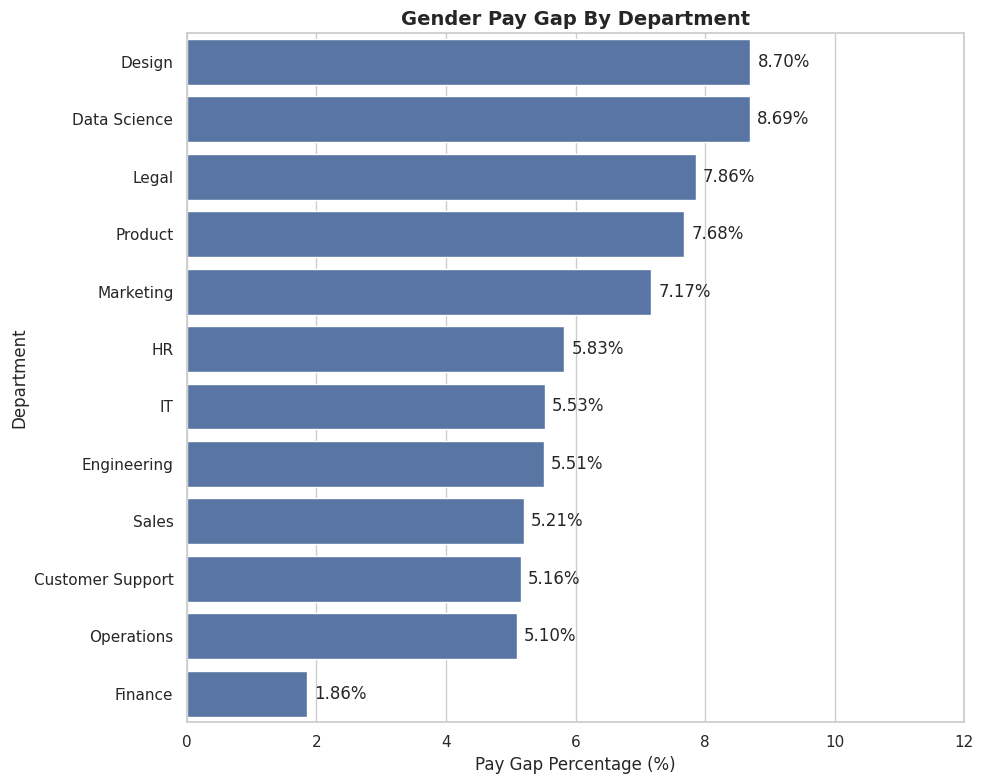

In [66]:
 # Import the libraries
import matplotlib.pyplot as plt
import seaborn as sns

#create a proffesional visual style
sns.set_theme(style='whitegrid')

# 1. Sort the dataframe correctly by pay gap percentage
sorted_dept_gap = dept_pivot.reset_index().sort_values('dept_pay_gap_percentage', ascending=False)

# 2. Create a clean canvas with enough height
fig, ax = plt.subplots(figsize=(10, 8))

# 3. Create the horizontal bar plot using the SORTED dataframe
bars=sns.barplot(
    data=sorted_dept_gap,
    x='dept_pay_gap_percentage',
    y='department',
    errorbar=None,
    ax=ax,

)

# 4. Format labels, title, and axis (starting at 0)
ax.set_xlabel('Pay Gap Percentage (%)', fontsize=12)
ax.set_ylabel('Department', fontsize=12)
ax.set_title('Gender Pay Gap By Department', fontsize=14, weight='bold')
ax.set_xlim(left=0, right=12)  # gives extra room on the right for text labels

#label the bars
ax.bar_label(bars.containers[0],fmt='%.2f%%',padding=5)

#save the image
plt.savefig('Gender_Pay_Gap_By_Department.png',bbox_inches='tight',dpi=300)

# 6. Display the plot cleanly
plt.tight_layout()
plt.show()

**2. Salary distribution: a histogram, shown for ok only.**

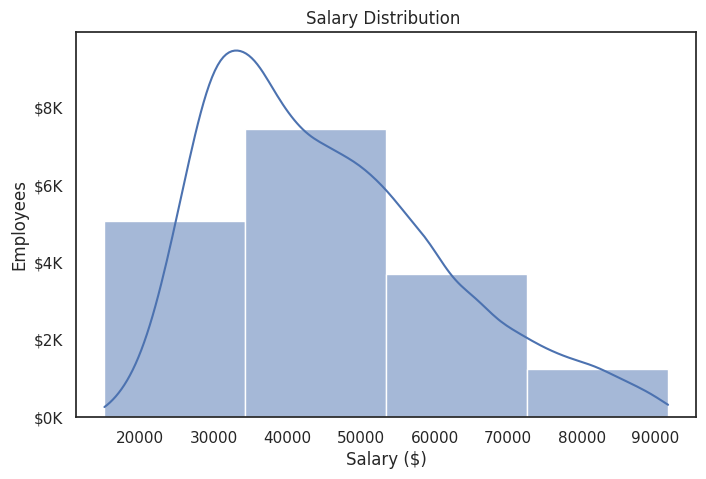

In [74]:
#set background visual style
sns.set_theme(style='white')


#create a canva
fig,ax=plt.subplots(figsize=(8,5))

#create ahistogram plot
sns.histplot(
    data=ok,
    x='salary_usd',
    bins=4,
    kde=True,
    ax=ax
)

#chart title
ax.set_title('Salary Distribution ')
ax.set_xlabel('Salary ($)')
ax.set_ylabel('Employees')


#import funcformater
from matplotlib.ticker import FuncFormatter
money_machine = FuncFormatter(lambda v, pos: f"${v/1000:.0f}K")
ax.yaxis.set_major_formatter(money_machine)

#save the image
plt.savefig('Salary_Distribution.png',bbox_inches='tight',dpi=300)

#display chart
plt.show()

**3 Relationship Between Salary and years of Experiance Scatter Chart**

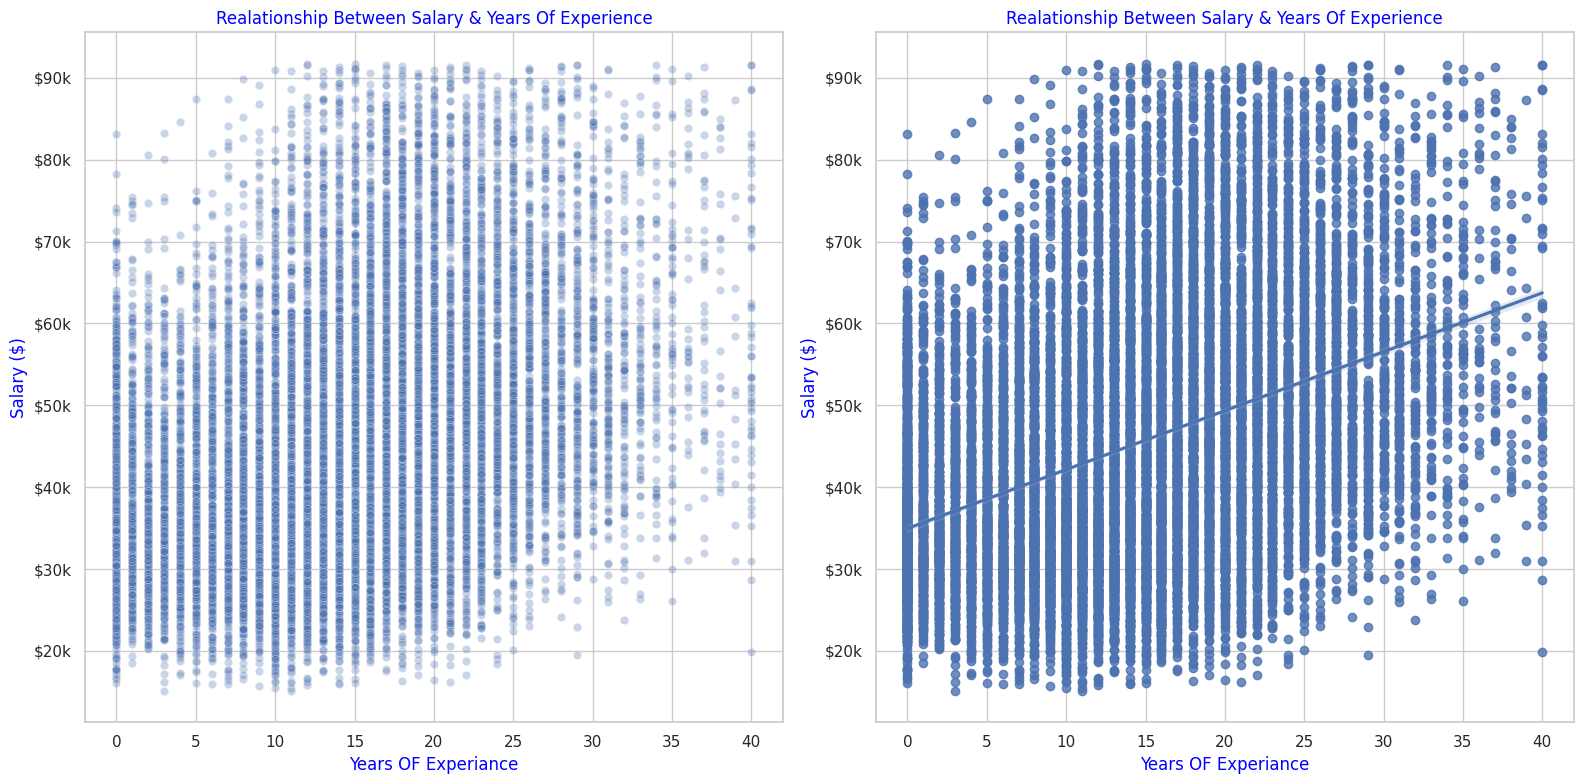

In [115]:
#scaterr plot
#set the background theme
sns.set_theme(style='whitegrid')

#create a canva and setup
fig,axis=plt.subplots(1,2,figsize=(16,8))

#creat on x scatter plot
sns.scatterplot(
    data=ok,
    x='years_experience',
    y='salary_usd',
    alpha=0.3,
    ax=axis[0]
)
axis[0].set_title('Realationship Between Salary & Years Of Experience',color='blue')
axis[0].set_xlabel('Years OF Experiance',color='blue')
axis[0].set_ylabel('Salary ($)',color='blue')

#standard the salary value
money_machine=FuncFormatter(lambda v , pos:f"${v/1000:.0f}k")
axis[0].yaxis.set_major_formatter(money_machine)

#creat on x scatter plot
sns.regplot(
    data=ok,
    x='years_experience',
    y='salary_usd',
    scatter=True,
    ax=axis[1]
)
axis[1].set_title('Realationship Between Salary & Years Of Experience',color='blue')
axis[1].set_xlabel('Years OF Experiance',color='blue')
axis[1].set_ylabel('Salary ($)',color='blue')


#standard the salary value
money_machine=FuncFormatter(lambda v , pos:f"${v/1000:.0f}k")
axis[1].yaxis.set_major_formatter(money_machine)


#save the fig
plt.savefig('Relationhip_Salary_&_Experience_Scatter.png',bbox_inches='tight',dpi=300)

#disply
fig.tight_layout()
plt.show()


**4. Average vs median salary by department: side-by-side bars, not stacked.**

In [ ]:
from IPython.core.pylabtools import figsize
dept_group=ok.groupby('department')['salary_usd'].agg(
    Average='mean',
    Median='median').reset_index()


#set the background style
sns.set_theme(style='whitegrid')

#create a canva
fig,ax=plt.subplots(figsize=(10,6))

#create abar plot on x axis
dept_group.plot(
    x='department',
    y=['Average','Median'],
    kind='bar',
    ax=ax
)

#set the tittle
ax.set_title('Average Vs Median Salary By Department',fontsize=14, weight='bold', pad=15)
ax.set_xlabel('Department',fontsize=12)
ax.set_ylabel('Salary USD',fontsize=12)
ax.legend(title='Salary Metric')
ax.set_ylim(0,60000)

#save the image
plt.savefig('Average_VS_Mean_Salary_By_Department',bbox_inches='tight',dpi=300)

#display
plt.tight_layout()
plt.show()



**4.Year Experiance Tenure_year Age Salary Usd Correlation using Heatmap Chart**

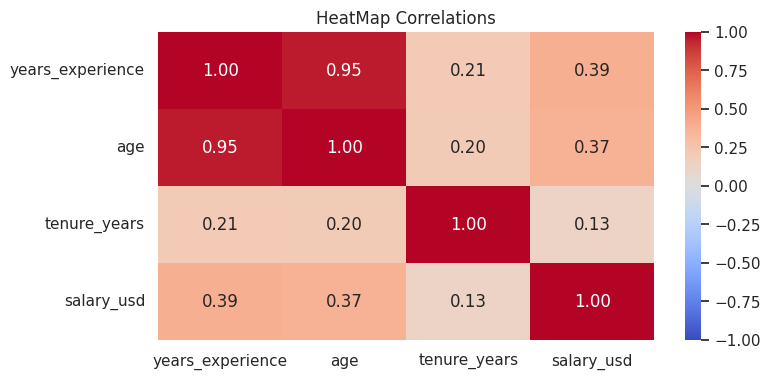

In [114]:
corr = ok[['years_experience', 'age', 'tenure_years', 'salary_usd']].corr()
corr

#create a cava and set up
fig,ax=plt.subplots(figsize=(8,4))

#create a eat map
sns.heatmap(
    corr,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    ax=ax
)

#set tittke
ax.set_title('HeatMap Correlations')

#save the chart
plt.savefig('Heatmap_correlations.png',bbox_inches='tight',dpi=300)

#display
plt.show()

# Stage 9: Ship it

# Python Pay Equtiy & Analysis Report

#  Problems

In Diffrent Country Every Company Can Create A company Report Based on The Gender Pay gap And Ethincity Pay Gap For Explain The In Comapny's No Gender Pay Equity And Ethincity. To Share Its Goverenance Yearly Report.

#  Bussiness Question

1. What is the disribution of employees across department, genders, paybands.
2. Is the salary getting based on experience,tenure Years,education level .
3. Is the Salary across all department its pay gap between gender.


# Data

1. It's a Kaggle dataset.
2. It's a real world live data set .
3. it data contain employeee details.
4. it data size 95k plus . but  i only use 18k data set.
5. I can check the first raw data it can messy data inncorect datatype  and incossitent formating ,its can contain blankspaces,uncessary symbol in currency and salary datatype is string and date is not dataformat,diffrent employee id can contain 'DUP' and not in oroper Format.
6. Before cleaning the data can 18k
7. After cleaning the dataset dat count is 17927
8. Using with salary outliar flag the employee count be 17464


#  Cleaning Descision

**Cleaning**
* checking te data types and formating .
* Removing the White spaces and Standardize the data set For the string datatype coloumn .
* Hire date can be a proper format and convert data type into the string to datetime data type.
* Removing the uncessary symbol and currency symbol and alphabets in salary coloumn and change the data type string and int into float datatypes Salary coloumn can convereted the based on currency country like INR, USD, EUR. .
* In employee id i can remove the duplicates id most id can unique but some id can contain the LEG and DUP.But i Cross Check the "DUP" the same employee id can contain te 'Dup' and employee id is same
it can the same id with dup it 73 employee id .
So i can remove the 73 employee id and they contain With "DUP'.

**Handling blanks**
* In the blenks value we can fill it carefully when the coloumns can can contain string data type i fill the mode values of coloumn means repeated values Expect(gender,remote_status,ethincity).
* in this three column i cannot fil the blank value with mode values i can use safe megod in the gender coloumn i can fill with 'perfer not to say',same ethincity and remote sataus  i fill balnk values with 'unkown'.

**Handling Outliars**
* After that i calcultae the Q1,Q2,IQR,upperbond,lowerbond and etc after a condition is when the lower bond is less than ouliar and greater than upper bond is the outliar so can easily diffrentiae and find out the outliar are present in coloumn or not.

* The outliar can store in salary outliar flag is yes it store all outliar.


#  Findings/Insights

 Department  by pay Gap
1. In  department the salary has distribution Pay Gap between 0% to 8% based on the gender and highest pay gap in Design department (8.07%) and lowest in finance(1.6%).


 Ethincity By Pay Gap
1. In the ethnicity i  check but it dosenot show the most gap by ethincity .
salary can be distributed 45k to 47k its not show high Pay Gap.

 Education level By Pay Gap
1. In education level is no edivence found to pay gap based on the eduction level .
every education level employees salary between 45k to 47k No pay gap diffrence found .

 Experiance VS Salary Correlation.
1. In this correlation i Check  when the
employee expeerience is increases and when teh salary also increases its slightly its corelation is (0.39) Moderate Pistive corelation.

Conclusion:-
1. Mangement Focusing on the departments salary pay is mostly in the departmentwise.


# Limitation

* I  use the current currency to is not a live currency it be a random acuurency not appropiate.
* For flaging outliar  we can use to lower bond 15000  but value less then  lower bond value in our data set its valid .
*  In hire date i can use the format the hire date as proffesionay with current date this is limitataions.


In [ ]:
dfc.to_excel("Pandas_Pay_Equity_Cleaned_Analysis.xlsx",index=False)